# Torus

A noisy sample of a 2-torus $\mathbb{T}^{2} \subset \mathbb{R}^{3}$, fit by a 2-variate trigonometric polynomial.


In [1]:
from dreimac import CircleMapUtils
from dreimac import GeometryExamples
from dreimac import PlotUtils
from dreimac import ToroidalCoords
from itertools import product
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
import plotly.io as pio
import torofit as TF

pio.renderers.default = "notebook_connected"

In [2]:

X = GeometryExamples.torus_3d(n_samples=2000, R=5, r=2)

In [3]:


# Plot the data 
fig = go.Figure(data=[go.Scatter3d(
    x=X[:,0], y=X[:,1], z=X[:,2], 
    mode ='markers', 
    marker=dict(size = 1.5 , color = 'grey'))])

fig.update_layout( width=900, height=450)
fig.show()

In [4]:
tc = ToroidalCoords(X, n_landmarks=200)
tc_theta = tc.get_coordinates(cocycle_idxs=[0,1])

In [5]:
fig = go.Figure(data=[go.Scatter3d(
    x=X[:,0], y=X[:,1], z=X[:,2], 
    mode ='markers', 
    marker=dict(size = 1.5 , color = CircleMapUtils.to_sinebow(tc_theta[0])))])

fig.update_layout( width=900, height=450)
fig.show()

In [6]:

#Toroidal Fitting params
K, lam = 15, 1.0

V = TF.fit(X, tc_theta.T, K=K, lam=lam) #Coefficient Matrix

In [7]:
# Plot the function generated by coefficient matrix V

def plot_function_via_coeff_matrix(V, K, d, samples=1000):
    '''
    Parameters
    ----------
    V : np.ndarray (2K+1)**d X N, coefficient matrix
    d : int, torus dimension
    K : int, bandwidth 

    Return
    ------
    res : np.ndarray samples**d X N, points sampled from f_V(T^d)
    '''

    theta = np.random.rand(samples, d)*2*np.pi
    res = TF.Toroidal_Evaluate(V, theta,K)
    return res

In [8]:
res = plot_function_via_coeff_matrix(V, K=K, d=2, samples=10000)

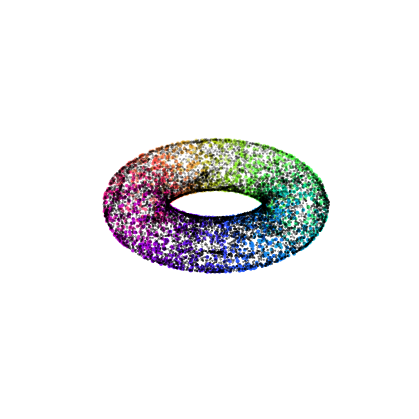

In [9]:

fig = plt.figure(figsize=(4,4))
ax = fig.add_subplot(projection="3d")
ax.scatter(X[:,0], X[:,1], X[:,2], s=3.0, c=CircleMapUtils.to_sinebow(tc_theta[0]))
ax.scatter(res[:,0], res[:,1], res[:,2], s=0.1, c='black')
PlotUtils.set_axes_equal(ax) ; plt.axis("off") ; fig.subplots_adjust(top=1, bottom=0, left=0, right=1)

In [10]:
perm = np.lexsort((res[:,0], res[:,1]))
res = res[perm]

In [11]:
N = 100
theta = np.linspace(0, 2*np.pi, num=N)
domain = np.asarray(list(product(theta, repeat=2))).T
image = TF.Toroidal_Evaluate(V,domain.T,K).real

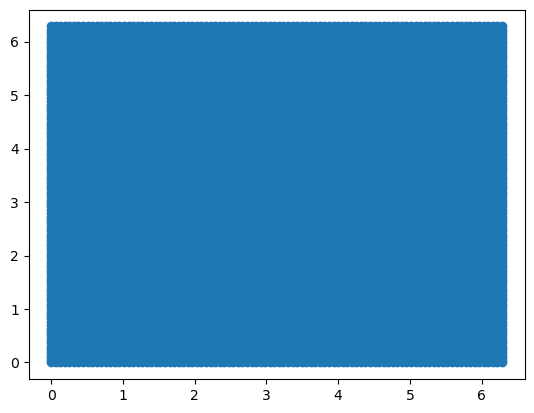

In [12]:
plt.scatter(domain[0,:], domain[1,:])
Is, Js, Ks = [], [], []
for i in np.arange(N):
    for j in np.arange(N):
        coord = i + N*j
        Is = Is + [coord,coord]
        Js = Js + [(coord + 1) % (N**2), (coord + N) % (N**2)]
        Ks = Ks + [(coord + 1 + N) % (N**2), (coord + 1 + N) % (N**2)]
triangles = np.column_stack([Is, Js, Ks])
t1 = mpl.tri.Triangulation(domain[0,:], domain[1,:], triangles=triangles)
plt.triplot(t1)

In [13]:
R,r = 5,2
n_samples=1000
X = np.zeros((n_samples, 3))
s = np.random.rand(n_samples) * 2 * np.pi
t = np.random.rand(n_samples) * 2 * np.pi
X[:, 0] = (R + r * np.cos(s)) * np.cos(t)
X[:, 1] = (R + r * np.cos(s)) * np.sin(t)
X[:, 2] = r * np.sin(s)

In [14]:
perm = np.lexsort(domain)
x, y, z = X[:,0],X[:,1], X[:,2]

fig = go.Figure(data=[go.Scatter3d(x=x, 
                                y=y, 
                                z=z,
                                 mode ='markers', 
    marker=dict(size = 1.5 , color = 'grey'))])
fig.update_layout( width=800, height=800)
fig.show()

In [15]:
perm = np.lexsort(domain)
x, y, z = image[:,0], image[:,1], image[:,2]

fig = go.Figure(data=[go.Mesh3d(x=x, 
                                y=y, 
                                z=z, 
                                color='cyan', 
                                opacity=0.50,
                                i=Is,
                                j=Js,
                                k=Ks)])
fig.show()

In [16]:

fig = go.Figure(data=[go.Scatter3d(x=X[:,0], 
                                y=X[:,1], 
                                z=X[:,2],
                                 mode ='markers', 
    marker=dict(size=2,color = 'grey')),
    go.Mesh3d(x=x, 
                                y=y, 
                                z=z, 
                                color='lightpink', 
                                colorscale=[[0, '#4B5AFA'],
                                        [0.25, '#4BFA7D'],
                                        [0.5, '#FA4B4B'],
                                        [0.75, '#FAD44B'],
                                         [1, '#4B5AFA']],
                                # Intensity of each vertex, which will be interpolated and color-coded
                                intensity = np.linspace(0, 1, N**2, endpoint=True),
                                opacity=0.50,
                                i=Is,
                                j=Js,
                                k=Ks)])

fig.update_layout( width=800, height=800)
fig.show()

